In [1]:
import pandas as pd
import atoti as tt
import numpy as np
import sqlite3

Welcome to Atoti 0.9.14!

By using this community edition, you agree with the license available at https://docs.activeviam.com/products/atoti/python-sdk/latest/eula.html.
Browse the official documentation at https://docs.activeviam.com/products/atoti/python-sdk.
Join the community at https://www.atoti.io/register.

Atoti collects telemetry data, which is used to help understand how to improve the product.
If you don't wish to send usage data, you can request a trial license at https://www.atoti.io/evaluation-license-request.

You can hide this message by setting the `ATOTI_HIDE_EULA_MESSAGE` environment variable to True.


# ETL

## Extract

In [2]:
customers = pd.read_csv("dataset warehouse/olist_customers_dataset.csv")
orders = pd.read_csv("dataset warehouse/olist_orders_dataset.csv")
order_items = pd.read_csv("dataset warehouse/olist_order_items_dataset.csv")
payments = pd.read_csv("dataset warehouse/olist_order_payments_dataset.csv")
products = pd.read_csv("dataset warehouse/olist_products_dataset.csv")
sellers = pd.read_csv("dataset warehouse/olist_sellers_dataset.csv")

In [3]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


## Transformasi 

### Cek Duplikasi Data

In [4]:
print(customers[customers.duplicated(subset=["customer_id"], keep=False)].sort_values("customer_id").head(8))
print(orders[orders.duplicated(subset=["order_id"], keep=False)].sort_values("order_id").head(8))
print(order_items[order_items.duplicated(subset=["order_id", "order_item_id"], keep=False)].sort_values("order_item_id").head(8))
print(payments[payments.duplicated(subset=["order_id", "payment_sequential"], keep=False)].sort_values("payment_sequential").head(8))
print(products[products.duplicated(subset=["product_id"], keep=False)].sort_values("product_id").head(8))
print(sellers[sellers.duplicated(subset=["seller_id"], keep=False)].sort_values("seller_id").head(8))

Empty DataFrame
Columns: [customer_id, customer_unique_id, customer_zip_code_prefix, customer_city, customer_state]
Index: []
Empty DataFrame
Columns: [order_id, customer_id, order_status, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date]
Index: []
Empty DataFrame
Columns: [order_id, order_item_id, product_id, seller_id, shipping_limit_date, price, freight_value]
Index: []
Empty DataFrame
Columns: [order_id, payment_sequential, payment_type, payment_installments, payment_value]
Index: []
Empty DataFrame
Columns: [product_id, product_category_name, product_name_lenght, product_description_lenght, product_photos_qty, product_weight_g, product_length_cm, product_height_cm, product_width_cm]
Index: []
Empty DataFrame
Columns: [seller_id, seller_zip_code_prefix, seller_city, seller_state]
Index: []


### Cek Nilai Kosong 

In [5]:
print(customers.isnull().sum())
print(orders.isnull().sum())
print(order_items.isnull().sum())
print(payments.isnull().sum())
print(products.isnull().sum())
print(sellers.isnull().sum())

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g   

### transformasi: products

<Axes: >

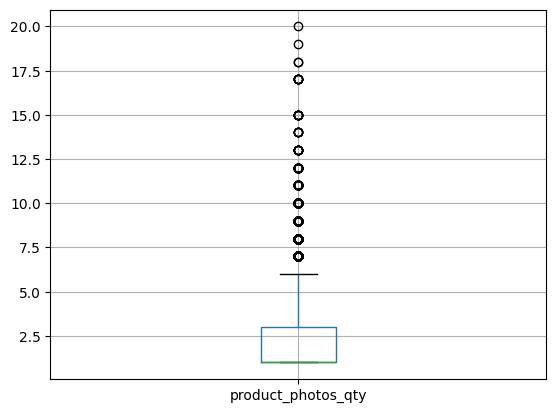

In [6]:
import matplotlib as plt
products.boxplot(column="product_photos_qty")

In [7]:
products["product_category_name"].unique().tolist()

['perfumaria',
 'artes',
 'esporte_lazer',
 'bebes',
 'utilidades_domesticas',
 'instrumentos_musicais',
 'cool_stuff',
 'moveis_decoracao',
 'eletrodomesticos',
 'brinquedos',
 'cama_mesa_banho',
 'construcao_ferramentas_seguranca',
 'informatica_acessorios',
 'beleza_saude',
 'malas_acessorios',
 'ferramentas_jardim',
 'moveis_escritorio',
 'automotivo',
 'eletronicos',
 'fashion_calcados',
 'telefonia',
 'papelaria',
 'fashion_bolsas_e_acessorios',
 'pcs',
 'casa_construcao',
 'relogios_presentes',
 'construcao_ferramentas_construcao',
 'pet_shop',
 'eletroportateis',
 'agro_industria_e_comercio',
 nan,
 'moveis_sala',
 'sinalizacao_e_seguranca',
 'climatizacao',
 'consoles_games',
 'livros_interesse_geral',
 'construcao_ferramentas_ferramentas',
 'fashion_underwear_e_moda_praia',
 'fashion_roupa_masculina',
 'moveis_cozinha_area_de_servico_jantar_e_jardim',
 'industria_comercio_e_negocios',
 'telefonia_fixa',
 'construcao_ferramentas_iluminacao',
 'livros_tecnicos',
 'eletrodomesti

In [8]:
products["product_photos_qty"] = products["product_photos_qty"].fillna(products["product_photos_qty"].median())
products["product_category_name"] = products["product_category_name"].fillna("unknown")
products["product_description_lenght"] = products["product_description_lenght"].fillna(products["product_description_lenght"].median())
products["product_name_lenght"] = products["product_name_lenght"].fillna(products["product_name_lenght"].mean())

In [9]:
products = products.dropna()

In [10]:
products.isnull().sum()

product_id                    0
product_category_name         0
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              0
product_length_cm             0
product_height_cm             0
product_width_cm              0
dtype: int64

### transformasi: customers

In [11]:
customers["customer_city"].unique().tolist()

['franca',
 'sao bernardo do campo',
 'sao paulo',
 'mogi das cruzes',
 'campinas',
 'jaragua do sul',
 'timoteo',
 'curitiba',
 'belo horizonte',
 'montes claros',
 'rio de janeiro',
 'lencois paulista',
 'caxias do sul',
 'piracicaba',
 'guarulhos',
 'pacaja',
 'florianopolis',
 'aparecida de goiania',
 'santo andre',
 'goiania',
 'cachoeiro de itapemirim',
 'sao jose dos campos',
 'sao roque',
 'camacari',
 'resende',
 'sumare',
 'novo hamburgo',
 'sao luis',
 'sao jose',
 'santa barbara',
 'ribeirao preto',
 'ituiutaba',
 'taquarituba',
 'sao jose dos pinhais',
 'barrinha',
 'parati',
 'dourados',
 'trindade',
 'cascavel',
 'fortaleza',
 'brasilia',
 'pelotas',
 'porto alegre',
 'salto',
 'jundiai',
 'cacapava',
 'sao vicente',
 'uberlandia',
 'botelhos',
 'sao goncalo',
 'araucaria',
 'nova iguacu',
 'areia branca',
 'campos dos goytacazes',
 'sao carlos',
 'itajuba',
 'cruz das almas',
 'vassouras',
 'feira de santana',
 'niteroi',
 'sobral',
 'divinopolis',
 'paraiba do sul',
 '

In [12]:
customers.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

### transformasi: order item

In [13]:
order_items["price"].unique().tolist()
order_items["freight_value"].unique().tolist()

[13.29,
 19.93,
 17.87,
 12.79,
 18.14,
 12.69,
 11.85,
 70.75,
 11.65,
 11.4,
 8.88,
 12.98,
 23.32,
 13.37,
 27.65,
 11.34,
 8.77,
 13.71,
 16.11,
 44.4,
 15.1,
 16.6,
 16.98,
 26.33,
 25.51,
 7.94,
 17.32,
 24.65,
 23.35,
 14.1,
 20.8,
 44.29,
 13.72,
 19.95,
 17.63,
 8.54,
 13.01,
 7.78,
 16.79,
 18.0,
 18.21,
 15.2,
 21.05,
 13.21,
 16.49,
 18.23,
 43.11,
 29.39,
 21.75,
 16.43,
 15.8,
 13.46,
 23.22,
 19.18,
 15.31,
 15.59,
 21.62,
 18.54,
 21.11,
 65.56,
 19.67,
 8.9,
 14.84,
 34.23,
 23.31,
 32.57,
 7.16,
 17.67,
 67.24,
 15.38,
 34.07,
 27.19,
 14.45,
 16.89,
 8.21,
 9.94,
 28.58,
 18.44,
 12.11,
 66.04,
 23.64,
 18.58,
 33.33,
 15.28,
 18.08,
 12.9,
 8.89,
 35.74,
 27.75,
 50.85,
 17.03,
 9.8,
 0.0,
 34.39,
 33.91,
 15.37,
 16.14,
 13.84,
 15.51,
 15.73,
 85.97,
 10.96,
 17.6,
 8.03,
 61.18,
 27.39,
 11.98,
 15.61,
 19.75,
 13.93,
 17.89,
 8.4,
 40.37,
 15.01,
 12.27,
 25.9,
 13.75,
 14.28,
 14.52,
 18.12,
 13.58,
 16.25,
 54.02,
 20.31,
 16.22,
 31.17,
 8.27,
 87.28,
 20.85,

In [14]:
order_items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

### transformasi: payments

In [15]:
payments["payment_type"].unique().tolist()

['credit_card', 'boleto', 'voucher', 'debit_card', 'not_defined']

In [16]:
payments.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

### transformasi: orders

In [17]:
orders["order_status"].unique().tolist()

['delivered',
 'invoiced',
 'shipped',
 'processing',
 'unavailable',
 'canceled',
 'created',
 'approved']

In [18]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [19]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [20]:
datetime_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date']

for col in datetime_cols:
    orders[col] = pd.to_datetime(orders[col])

In [21]:
avg_approval_delay = (orders['order_approved_at'] - orders['order_purchase_timestamp']).mean()
orders['order_approved_at'] = orders['order_approved_at'].fillna(orders['order_purchase_timestamp'] + avg_approval_delay)

In [22]:
avg_carrier_delay = (orders['order_delivered_carrier_date'] -orders['order_approved_at']).mean()
orders['order_delivered_carrier_date'] = orders['order_delivered_carrier_date'].fillna(orders['order_approved_at'] + avg_carrier_delay)

In [23]:
avg_customer_delay = (orders['order_delivered_customer_date'] -orders['order_delivered_carrier_date']).mean()
orders['order_delivered_customer_date'] = orders['order_delivered_customer_date'].fillna(orders['order_delivered_carrier_date'] + avg_customer_delay)

In [24]:
orders.isnull().sum()

order_id                         0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64

In [25]:
# waktu purchase
orders["purchase_year"] = orders["order_purchase_timestamp"].dt.year.astype(str)
orders["purchase_month"] = orders["order_purchase_timestamp"].dt.month.astype(str)
orders["purchase_day"] = orders["order_purchase_timestamp"].dt.day.astype(str)
orders["purchase_hour"] = orders["order_purchase_timestamp"].dt.hour.astype(str)
orders["purchase_minute"] = orders["order_purchase_timestamp"].dt.minute.astype(str)
orders["purchase_second"] = orders["order_purchase_timestamp"].dt.second.astype(str)

In [26]:
# waktu approve
orders["approve_year"] = orders["order_approved_at"].dt.year.astype(str)
orders["approve_month"] = orders["order_approved_at"].dt.month.astype(str)
orders["approve_day"] = orders["order_approved_at"].dt.day.astype(str)
orders["approve_hour"] = orders["order_approved_at"].dt.hour.astype(str)
orders["approve_minute"] = orders["order_approved_at"].dt.minute.astype(str)
orders["approve_second"] = orders["order_approved_at"].dt.second.astype(str)

In [27]:
# waktu delivered carrier
orders["carrier_year"] = orders["order_delivered_carrier_date"].dt.year.astype(str)
orders["carrier_month"] = orders["order_delivered_carrier_date"].dt.month.astype(str)
orders["carrier_day"] = orders["order_delivered_carrier_date"].dt.day.astype(str)
orders["carrier_hour"] = orders["order_delivered_carrier_date"].dt.hour.astype(str)
orders["carrier_minute"] = orders["order_delivered_carrier_date"].dt.minute.astype(str)
orders["carrier_second"] = orders["order_delivered_carrier_date"].dt.second.astype(str)

In [28]:
# waktu delivered customer
orders["customer_year"] = orders["order_delivered_customer_date"].dt.year.astype(str)
orders["customer_month"] = orders["order_delivered_customer_date"].dt.month.astype(str)
orders["customer_day"] = orders["order_delivered_customer_date"].dt.day.astype(str)
orders["customer_hour"] = orders["order_delivered_customer_date"].dt.hour.astype(str)
orders["customer_minute"] = orders["order_delivered_customer_date"].dt.minute.astype(str)
orders["customer_second"] = orders["order_delivered_customer_date"].dt.second.astype(str)

In [29]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 32 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99441 non-null  datetime64[ns]
 5   order_delivered_carrier_date   99441 non-null  datetime64[ns]
 6   order_delivered_customer_date  99441 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  object        
 8   purchase_year                  99441 non-null  object        
 9   purchase_month                 99441 non-null  object        
 10  purchase_day                   99441 non-null  object        
 11  purchase_hour  

### transformasi: sellers

In [30]:
sellers["seller_city"].unique().tolist()

['campinas',
 'mogi guacu',
 'rio de janeiro',
 'sao paulo',
 'braganca paulista',
 'brejao',
 'penapolis',
 'curitiba',
 'anapolis',
 'itirapina',
 'tubarao',
 'lauro de freitas',
 'imbituba',
 'brasilia',
 'porto seguro',
 'guaruja',
 'tabatinga',
 'salto',
 'tres de maio',
 'belo horizonte',
 'arapongas',
 'sao bernardo do campo',
 'tatui',
 'garopaba',
 'camanducaia',
 'tupa',
 'guarulhos',
 'sao jose dos pinhais',
 'sao ludgero',
 'sao jose',
 'piracicaba',
 'porto alegre',
 'congonhal',
 'santo andre',
 'osasco',
 'valinhos',
 'joinville',
 'saquarema',
 'barra velha',
 'petropolis',
 'santo antonio da patrulha',
 'ponta grossa',
 'santana de parnaiba',
 'sao carlos',
 'ibitinga',
 'barueri',
 'caxias do sul',
 'araguari',
 'contagem',
 'jaragua do sul',
 'lages - sc',
 'bento goncalves',
 'catanduva',
 'ribeirao pires',
 'jaboticabal',
 'echapora',
 'cotia',
 'rio do sul',
 'sorocaba',
 'pradopolis',
 'itaborai',
 'mirassol',
 'birigui',
 'assis',
 'jaguariuna',
 'araraquara',
 

In [31]:
sellers.isnull().sum()

seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

In [32]:
seller_city_map = {"sao paulo / sao paulo":"sao paulo", "sp / sp":"sao paulo", "sp":"sao paulo",
                   "sao paulo - sp":"sao paulo", "rio de janeiro \\rio de janeiro":"rio de janeiro", "rio de janeiro / rio de janeiro":"rio de janeiro",
                   "rio de janeiro, rio de janeiro, brasil":"rio de janeiro", "sao paulop":"sao paulo", "04482255":"unknown",
                   "vendas@creditparts.com.br":"unknown"}

sellers["seller_city"] = sellers["seller_city"].replace(seller_city_map)

In [33]:
sellers["seller_city"].unique().tolist()

['campinas',
 'mogi guacu',
 'rio de janeiro',
 'sao paulo',
 'braganca paulista',
 'brejao',
 'penapolis',
 'curitiba',
 'anapolis',
 'itirapina',
 'tubarao',
 'lauro de freitas',
 'imbituba',
 'brasilia',
 'porto seguro',
 'guaruja',
 'tabatinga',
 'salto',
 'tres de maio',
 'belo horizonte',
 'arapongas',
 'sao bernardo do campo',
 'tatui',
 'garopaba',
 'camanducaia',
 'tupa',
 'guarulhos',
 'sao jose dos pinhais',
 'sao ludgero',
 'sao jose',
 'piracicaba',
 'porto alegre',
 'congonhal',
 'santo andre',
 'osasco',
 'valinhos',
 'joinville',
 'saquarema',
 'barra velha',
 'petropolis',
 'santo antonio da patrulha',
 'ponta grossa',
 'santana de parnaiba',
 'sao carlos',
 'ibitinga',
 'barueri',
 'caxias do sul',
 'araguari',
 'contagem',
 'jaragua do sul',
 'lages - sc',
 'bento goncalves',
 'catanduva',
 'ribeirao pires',
 'jaboticabal',
 'echapora',
 'cotia',
 'rio do sul',
 'sorocaba',
 'pradopolis',
 'itaborai',
 'mirassol',
 'birigui',
 'assis',
 'jaguariuna',
 'araraquara',
 

## Load Atoti

In [34]:
session = tt.Session.start()

In [35]:
customers_table = session.read_pandas(customers, table_name="customers")
orders_table = session.read_pandas(orders, table_name="orders")
order_items_table = session.read_pandas(order_items, table_name="order_items")
payments_table = session.read_pandas(payments, table_name="payments")
products_table = session.read_pandas(products, table_name="products")
sellers_table = session.read_pandas(sellers, table_name="sellers")

In [36]:
# customers -> orders
orders_table.join(customers_table, orders_table["customer_id"] == customers_table["customer_id"])

# orders -> order_items
order_items_table.join(orders_table, order_items_table["order_id"] == orders_table["order_id"])

# orders -> payments
payments_table.join(orders_table, payments_table["order_id"] == orders_table["order_id"])

# products -> order_items
order_items_table.join(products_table, order_items_table["product_id"] == products_table["product_id"])

# sellers -> order_items
order_items_table.join(sellers_table, order_items_table["seller_id"] == sellers_table["seller_id"])

In [37]:
session.tables.schema

```mermaid
erDiagram
  "customers" {
    non-null String "customer_id"
    non-null String "customer_unique_id"
    nullable long "customer_zip_code_prefix"
    non-null String "customer_city"
    non-null String "customer_state"
  }
  "orders" {
    non-null String "order_id"
    non-null String "customer_id"
    non-null String "order_status"
    non-null LocalDateTime "order_purchase_timestamp"
    non-null LocalDateTime "order_approved_at"
    non-null LocalDateTime "order_delivered_carrier_date"
    non-null LocalDateTime "order_delivered_customer_date"
    non-null String "order_estimated_delivery_date"
    non-null String "purchase_year"
    non-null String "purchase_month"
    non-null String "purchase_day"
    non-null String "purchase_hour"
    non-null String "purchase_minute"
    non-null String "purchase_second"
    non-null String "approve_year"
    non-null String "approve_month"
    non-null String "approve_day"
    non-null String "approve_hour"
    non-null String "approve_minute"
    non-null String "approve_second"
    non-null String "carrier_year"
    non-null String "carrier_month"
    non-null String "carrier_day"
    non-null String "carrier_hour"
    non-null String "carrier_minute"
    non-null String "carrier_second"
    non-null String "customer_year"
    non-null String "customer_month"
    non-null String "customer_day"
    non-null String "customer_hour"
    non-null String "customer_minute"
    non-null String "customer_second"
  }
  "order_items" {
    non-null String "order_id"
    nullable long "order_item_id"
    non-null String "product_id"
    non-null String "seller_id"
    non-null String "shipping_limit_date"
    nullable double "price"
    nullable double "freight_value"
  }
  "payments" {
    non-null String "order_id"
    nullable long "payment_sequential"
    non-null String "payment_type"
    nullable long "payment_installments"
    nullable double "payment_value"
  }
  "products" {
    non-null String "product_id"
    non-null String "product_category_name"
    nullable double "product_name_lenght"
    nullable double "product_description_lenght"
    nullable double "product_photos_qty"
    nullable double "product_weight_g"
    nullable double "product_length_cm"
    nullable double "product_height_cm"
    nullable double "product_width_cm"
  }
  "sellers" {
    non-null String "seller_id"
    nullable long "seller_zip_code_prefix"
    non-null String "seller_city"
    non-null String "seller_state"
  }
  "orders" }o--o| "customers" : "customer_id == customer_id"
  "order_items" }o--o| "orders" : "order_id == order_id"
  "order_items" }o--o| "products" : "product_id == product_id"
  "order_items" }o--o| "sellers" : "seller_id == seller_id"
  "payments" }o--o| "orders" : "order_id == order_id"
```


# CUBE

In [38]:
cube = session.create_cube(order_items_table)
h = cube.hierarchies
l = cube.levels
m = cube.measures

#Hierarki Lokasi Seller
h["Geography_Seller"] = [sellers_table["seller_state"], sellers_table["seller_city"]] #mau pakai nama tabel atau "l", bebas
h["Geography_Seller"].dimension = "Location"
del h["seller_state"], h["seller_city"]

#Hierarki Waktu purchase
h["Purchase_Time"] = [orders_table["purchase_year"], orders_table["purchase_month"], orders_table["purchase_day"], orders_table["purchase_hour"], orders_table["purchase_minute"], orders_table["purchase_second"]]
h["Purchase_Time"].dimension = "Time"
del h["purchase_year"], h["purchase_month"], h["purchase_day"], h["purchase_hour"], h["purchase_minute"], h["purchase_second"]

#Hierarki waktu approve
h["Approve_Time"] = [l["approve_year"], l["approve_month"], l["approve_day"], l["approve_hour"], l["approve_minute"], l["approve_second"]]
h["Approve_Time"].dimension = "Time"
del h["approve_year"], h["approve_month"], h["approve_day"], h["approve_hour"], h["approve_minute"], h["approve_second"]

#Hierarki Waktu Delivered Carrier
h["Carrier_Time"] = [l["carrier_year"], l["carrier_month"], l["carrier_day"], l["carrier_hour"], l["carrier_minute"], l["carrier_second"]]
h["Carrier_Time"].dimension = "Time"
del h["carrier_year"], h["carrier_month"], h["carrier_day"], h["carrier_hour"], h["carrier_minute"], h["carrier_second"]

#Hierarki Waktu Delivered Customer
h["Customer_Time"] = [l["customer_year"], l["customer_month"], l["customer_day"], l["customer_hour"], l["customer_minute"], l["customer_second"]]
h["Customer_Time"].dimension = "Time"
del h["customer_year"], h["customer_month"], h["customer_day"], h["customer_hour"], h["customer_minute"], h["customer_second"]

#Hierarki Lokasi Kustomer
h["Geography_Customer"] = [l["customer_state"], l["customer_city"]]
h["Geography_Customer"].dimension = "Location"
del h["customer_state"], h["customer_city"]

#Hierarki Product
h["Product"] = [products_table["product_category_name"],products_table["product_id"]]
h["Product"].dimension = "Product"
del h["product_category_name"], h["product_id"]

#Measure Revenue
m["Revenue"] = tt.agg.sum(order_items_table["price"])

#Measure Total Freight
m["Total_Freight"] = tt.agg.sum(order_items_table["freight_value"])

#Measure Total Order
m["Total_Order"] = tt.agg.count_distinct(orders_table["order_id"])

#Measure Average Revenue
m["Average_Revenue"] = tt.agg.mean(order_items_table["price"])

### Query Insight

In [39]:
#Total Revenue
cube.query(m["Revenue"])

,Revenue
0,"13,591,643.70"


In [40]:
#Total Order
cube.query(m["Total_Order"])

,Total_Order
0,"98,666"


In [41]:
#Revenue Berdasarkan Kategori Produk
cube.query( m["Revenue"], levels=[l["product_category_name"]] )

,Revenue
product_category_name,
N/A,"2,497.00"
agro_industria_e_comercio,"72,530.47"
alimentos,"29,393.41"
alimentos_bebidas,"15,179.48"
artes,"24,202.64"
...,...
tablets_impressao_imagem,"7,528.41"
telefonia,"323,667.53"
telefonia_fixa,"59,583.00"


In [42]:
#Total Order Berdasarkan Wilayah Customer
cube.query( m["Total_Order"], levels=[l["customer_state"], l["customer_city"]] )

Total_Order
customer_state customer_city                      
AC             brasileia                         1
               cruzeiro do sul                   3
               epitaciolandia                    1
               manoel urbano                     1
               porto acre                        1
...                                            ...
TO             silvanopolis                      1
               sitio novo do tocantins           2
               taguatinga                        3
               tocantinopolis                    7
               xambioa                           3

[4300 rows x 1 columns]

In [43]:
#Revenue Berdasarkan Waktu Transaksi
cube.query( m["Revenue"], levels=[l["purchase_year"], l["purchase_month"]] )

Revenue
purchase_year purchase_month              
2016          10                 49,507.66
              12                     10.90
              9                     267.36
2017          1                 120,312.87
              10                664,219.43
              11              1,010,271.37
              12                743,914.17
              2                 247,303.02
              3                 374,344.30
              4                 359,927.23
              5                 506,071.14
              6                 433,038.60
              7                 498,031.48
              8                 573,971.68
              9                 624,401.69
2018          1                 950,030.36
              2                 844,178.71
              3                 983,213.44
              4                 996,647.75
              5                 996,517.68
              6                 865,124.31
              7                 895,507.22
              8                 854,686.33
              9                     145.00

In [44]:
#Total Freight Berdasarkan Wilayah Customer
cube.query( m["Total_Freight"], levels=[l["customer_state"]] )

,Total_Freight
customer_state,
AC,"3,686.75"
AL,"15,914.59"
AM,"5,478.89"
AP,"2,788.50"
BA,"100,156.68"
CE,"48,351.59"
DF,"50,625.50"
ES,"49,764.60"
GO,"53,114.98"


Open the notebook in JupyterLab with the Atoti JupyterLab extension enabled to build this widget.
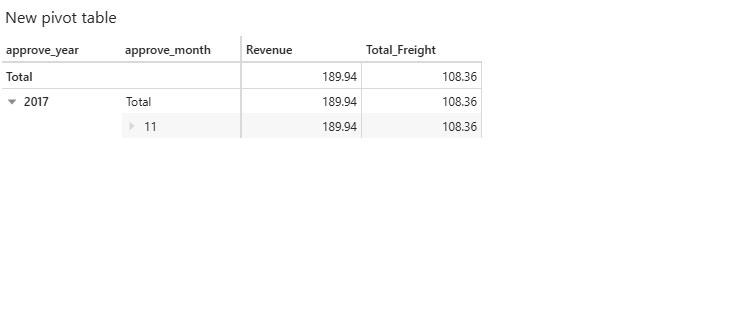

In [45]:
session.widget

# DATA MART

In [46]:
session_sales = tt.Session.start()
session_product = tt.Session.start()
session_logistic = tt.Session.start()

## Load ke SQLite

In [47]:
dw = sqlite3.connect("olist_dw.db")

customers.to_sql("customers", dw, if_exists="replace", index=False)
orders.to_sql("orders", dw, if_exists="replace", index=False)
order_items.to_sql("order_items", dw, if_exists="replace", index=False)
payments.to_sql("payments", dw, if_exists="replace", index=False)
products.to_sql("products", dw, if_exists="replace", index=False)
sellers.to_sql("sellers", dw, if_exists="replace", index=False)

3095

## Sales Mart

### Fact Table

In [48]:
query_sales = """
    select
        oi.order_id,
        c.customer_id,
        p.product_id,
        oi.freight_value,
        oi.price,
        o.purchase_year,
        o.purchase_month,
        o.purchase_day
    from order_items oi
    join orders o
        on oi.order_id = o.order_id
    join customers c
        on o.customer_id = c.customer_id
    join products p
        on oi.product_id = p.product_id;
"""

fact_sales = pd.read_sql(query_sales, dw)
fact_sales.head()

,order_id,customer_id,product_id,freight_value,price,purchase_year,purchase_month,purchase_day
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,4244733e06e7ecb4970a6e2683c13e61,13.29,58.90,2017,9,13
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,e5f2d52b802189ee658865ca93d83a8f,19.93,239.90,2017,4,26
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,c777355d18b72b67abbeef9df44fd0fd,17.87,199.00,2018,1,14
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,7634da152a4610f1595efa32f14722fc,12.79,12.99,2018,8,8
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,ac6c3623068f30de03045865e4e10089,18.14,199.90,2017,2,4


### Dimension Table

In [49]:
query_sales2 = """
    select
        customer_id,
        customer_state,
        customer_city
    from customers"""

dim_customer = pd.read_sql(query_sales2, dw) 
dim_customer.head()

,customer_id,customer_state,customer_city
0,06b8999e2fba1a1fbc88172c00ba8bc7,SP,franca
1,18955e83d337fd6b2def6b18a428ac77,SP,sao bernardo do campo
2,4e7b3e00288586ebd08712fdd0374a03,SP,sao paulo
3,b2b6027bc5c5109e529d4dc6358b12c3,SP,mogi das cruzes
4,4f2d8ab171c80ec8364f7c12e35b23ad,SP,campinas


In [50]:
query_sales3 = """
    select
        product_id,
        product_category_name
    from products"""

dim_product = pd.read_sql(query_sales3, dw)
dim_product.head()

,product_id,product_category_name
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria
1,3aa071139cb16b67ca9e5dea641aaa2f,artes
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer
3,cef67bcfe19066a932b7673e239eb23d,bebes
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas


### Simpan ke SQLite Terpisah

In [51]:
sales_db = sqlite3.connect("db_mart/sales_mart.db")

fact_sales.to_sql("fact_sales", sales_db, if_exists="replace", index=False)
dim_customer.to_sql("dim_customer", sales_db, if_exists="replace", index=False)
dim_product.to_sql("dim_product", sales_db, if_exists="replace", index=False)

32949

### Simpan Ke CSV

In [52]:
fact_sales.to_csv("data_mart/csv_sales/fact_sales.csv", index=False)
dim_customer.to_csv("data_mart/csv_sales/dim_customer.csv", index=False)
dim_product.to_csv("data_mart/csv_sales/dim_product.csv", index=False)

### Data Dari CSV + Join Untuk Star Schema

In [53]:
fact_sales_tbl = session_sales.read_csv("data_mart/csv_sales/fact_sales.csv", keys={"order_id"})
dim_customer_tbl = session_sales.read_csv("data_mart/csv_sales/dim_customer.csv", keys={"customer_id"})
dim_product_tbl = session_sales.read_csv("data_mart/csv_sales/dim_product.csv", keys={"product_id"})

fact_sales_tbl.join(dim_customer_tbl, fact_sales_tbl["customer_id"] == dim_customer_tbl["customer_id"])
fact_sales_tbl.join(dim_product_tbl, fact_sales_tbl["product_id"] == dim_product_tbl["product_id"])

session_sales.tables.schema

C:\Users\fazlur\atoti2\Lib\site-packages\atoti\_opentelemetry\span.py:44: FutureWarning: Inferring `table_name` from `path` is deprecated, pass a `table_name` argument instead.
  return func(*args, **kwargs)  # type: ignore[no-any-return]


```mermaid
erDiagram
  "Fact_sales" {
    non-null String PK "order_id"
    non-null String "customer_id"
    non-null String "product_id"
    nullable double "freight_value"
    nullable double "price"
    nullable int "purchase_year"
    nullable int "purchase_month"
    nullable int "purchase_day"
  }
  "Dim_customer" {
    non-null String PK "customer_id"
    non-null String "customer_state"
    non-null String "customer_city"
  }
  "Dim_product" {
    non-null String PK "product_id"
    non-null String "product_category_name"
  }
  "Fact_sales" }o--o| "Dim_customer" : "customer_id == customer_id"
  "Fact_sales" }o--o| "Dim_product" : "product_id == product_id"
```


## Product Mart

### Fact Table

In [54]:
query_product = """
    select
        oi.order_id,
        oi.product_id,
        oi.price,
        oi.freight_value,
        o.purchase_year,
        o.purchase_month,
        o.purchase_day
    from order_items oi
    join orders o
        on oi.order_id = o.order_id"""

fact_product = pd.read_sql(query_product, dw)
fact_product.head()

,order_id,product_id,price,freight_value,purchase_year,purchase_month,purchase_day
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,58.90,13.29,2017,9,13
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,239.90,19.93,2017,4,26
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,199.00,17.87,2018,1,14
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,12.99,12.79,2018,8,8
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,199.90,18.14,2017,2,4


### Dimension Table

In [55]:
query_product2 = """
    select
        product_id,
        product_category_name
    from products"""

product_dim_product = pd.read_sql(query_product2, dw)
product_dim_product.head()

,product_id,product_category_name
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria
1,3aa071139cb16b67ca9e5dea641aaa2f,artes
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer
3,cef67bcfe19066a932b7673e239eb23d,bebes
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas


### Simpan ke SQLite Terpisah

In [56]:
product_db = sqlite3.connect("db_mart/product_mart.db")

fact_product.to_sql("fact_product", product_db, if_exists="replace", index=False)
product_dim_product.to_sql("dim_product", product_db, if_exists="replace", index=False)

32949

### Simpan Ke CSV

In [57]:
fact_product.to_csv("data_mart/csv_product/fact_product.csv", index=False)
product_dim_product.to_csv("data_mart/csv_product/dim_product.csv", index=False)

### Data Dari CSV + Join Untuk Star Schema

In [58]:
fact_product_tbl = session_product.read_csv("data_mart/csv_product/fact_product.csv", keys={"order_id"})
dim_product_tbl = session_product.read_csv("data_mart/csv_product/dim_product.csv", keys={"product_id"})

fact_product_tbl.join(dim_product_tbl, fact_product_tbl["product_id"] == dim_product_tbl["product_id"])

session_product.tables.schema

C:\Users\fazlur\atoti2\Lib\site-packages\atoti\_opentelemetry\span.py:44: FutureWarning: Inferring `table_name` from `path` is deprecated, pass a `table_name` argument instead.
  return func(*args, **kwargs)  # type: ignore[no-any-return]


```mermaid
erDiagram
  "Fact_product" {
    non-null String PK "order_id"
    non-null String "product_id"
    nullable double "price"
    nullable double "freight_value"
    nullable int "purchase_year"
    nullable int "purchase_month"
    nullable int "purchase_day"
  }
  "Dim_product" {
    non-null String PK "product_id"
    non-null String "product_category_name"
  }
  "Fact_product" }o--o| "Dim_product" : "product_id == product_id"
```


## Logistic Mart

### Fact Table

In [59]:
query_logistic = """
    select
        oi.order_id,
        c.customer_id,
        oi.freight_value,
        o.order_purchase_timestamp,
        o.order_delivered_customer_date,
        o.order_estimated_delivery_date
    from order_items oi
    join orders o
        on oi.order_id = o.order_id
    join customers c
        on o.customer_id = c.customer_id"""

fact_logistic = pd.read_sql(query_logistic, dw)
fact_logistic.head()

,order_id,customer_id,freight_value,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,13.29,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29 00:00:00
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,19.93,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15 00:00:00
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,17.87,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05 00:00:00
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,12.79,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20 00:00:00
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,18.14,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17 00:00:00


### Dimension Table

In [60]:
query_logistic2 = """
    select
        customer_id,
        customer_state,
        customer_city
    from customers"""

logistic_dim_customer = pd.read_sql(query_logistic2, dw)
logistic_dim_customer.head()

,customer_id,customer_state,customer_city
0,06b8999e2fba1a1fbc88172c00ba8bc7,SP,franca
1,18955e83d337fd6b2def6b18a428ac77,SP,sao bernardo do campo
2,4e7b3e00288586ebd08712fdd0374a03,SP,sao paulo
3,b2b6027bc5c5109e529d4dc6358b12c3,SP,mogi das cruzes
4,4f2d8ab171c80ec8364f7c12e35b23ad,SP,campinas


### Simpan Ke SQLite Terpisah

In [61]:
logistic_db = sqlite3.connect("db_mart/logistic_mart.db")

fact_logistic.to_sql("fact_logistic", logistic_db, if_exists="replace", index=False)
logistic_dim_customer.to_sql("dim_product", logistic_db, if_exists="replace", index=False)

99441

### Simpan Ke CSV

In [62]:
fact_logistic.to_csv("data_mart/csv_logistic/fact_logistic.csv", index=False)
logistic_dim_customer.to_csv("data_mart/csv_logistic/dim_customer.csv", index=False)

### Data Dari CSV + Join Untuk Star Schema

In [63]:
fact_logistic_tbl = session_logistic.read_csv("data_mart/csv_logistic/fact_logistic.csv", keys={"order_id"})
dim_customer_tbl = session_logistic.read_csv("data_mart/csv_logistic/dim_customer.csv", keys={"customer_id"})

fact_logistic_tbl.join(dim_customer_tbl, fact_logistic_tbl["customer_id"] == dim_customer_tbl["customer_id"])

session_logistic.tables.schema

C:\Users\fazlur\atoti2\Lib\site-packages\atoti\_opentelemetry\span.py:44: FutureWarning: Inferring `table_name` from `path` is deprecated, pass a `table_name` argument instead.
  return func(*args, **kwargs)  # type: ignore[no-any-return]


```mermaid
erDiagram
  "Fact_logistic" {
    non-null String PK "order_id"
    non-null String "customer_id"
    nullable double "freight_value"
    non-null String "order_purchase_timestamp"
    non-null String "order_delivered_customer_date"
    non-null String "order_estimated_delivery_date"
  }
  "Dim_customer" {
    non-null String PK "customer_id"
    non-null String "customer_state"
    non-null String "customer_city"
  }
  "Fact_logistic" }o--o| "Dim_customer" : "customer_id == customer_id"
```


## Query Test

In [64]:
pd.read_sql("select * from fact_logistic", logistic_db)

,order_id,customer_id,freight_value,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,13.29,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29 00:00:00
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,19.93,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15 00:00:00
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,17.87,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05 00:00:00
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,12.79,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20 00:00:00
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,18.14,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17 00:00:00
...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,b51593916b4b8e0d6f66f2ae24f2673d,43.41,2018-04-23 13:57:06,2018-05-10 22:56:40,2018-05-18 00:00:00
112646,fffcd46ef2263f404302a634eb57f7eb,84c5d4fbaf120aae381fad077416eaa0,36.53,2018-07-14 10:26:46,2018-07-23 20:31:55,2018-08-01 00:00:00
112647,fffce4705a9662cd70adb13d4a31832d,29309aa813182aaddc9b259e31b870e6,16.95,2017-10-23 17:07:56,2017-10-28 12:22:22,2017-11-10 00:00:00
112648,fffe18544ffabc95dfada21779c9644f,b5e6afd5a41800fdf401e0272ca74655,8.72,2017-08-14 23:02:59,2017-08-16 21:59:40,2017-08-25 00:00:00
